In [1]:
%pip install numpy matplotlib scipy > /dev/null
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
import kalman
kalman.set_debug(0)


[notice] A new release of pip is available: 26.0.1 -> 26.1.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# Combinatorial Kalman Filter — Track Finding

Most Kalman filters estimate **one** trajectory from a stream of single measurements. A particle
detector poses a harder problem: each detector layer records **many hits** — several real particles
*plus* background — and we do not know in advance which hit belongs to which track. Reconstructing
the tracks is therefore **combinatorial**.

The **Combinatorial Kalman Filter (CKF)** solves it by *track following*: starting from a seed, it
walks outward layer by layer, and at each layer

1. **predicts** where the track should cross the next layer (Kalman predict through the magnetic field),
2. **gates** every hit on that layer by its innovation $\chi^2$ and opens a **branch** for each hit that
   passes (plus a *hole* branch for detector inefficiency),
3. **prunes** the growing tree of candidates to a bounded beam of the best ones, and finally
4. **arbitrates** shared hits so the reported tracks are disjoint.

This is the algorithm behind modern trackers such as Belle II
([BELLE2-PTHESIS-2019-002](https://docs.belle2.org/files/4163/BELLE2-PTHESIS-2019-002/1/BELLE2-PTHESIS-2019-002.pdf)).
Here we run it on a pedagogical 2-D transverse tracker: a charged particle bending in a uniform field
$B_z$, sampled on concentric cylindrical layers (the CDC analogue).

## The detector model

`DriftChamberModel` represents the system. The **state** is $x = [x, y, p_x, p_y]$ (transverse
position and momentum); the field makes the trajectory a circular arc of curvature
$1/R = qB_z/|p|$. Propagation `f(x, t=r)` advances the arc to the next **layer radius** $r$, and the
measurement `h(x) = [x, y]` is the crossing position. The model also **generates synthetic events**
with its own propagator, so truth and filter are perfectly consistent.

In [2]:
from kalman.apps import DriftChamberModel

model = DriftChamberModel(n_layers=8, r_inner=1.0, r_step=1.0, Bz=0.05, sigma_hit=0.05)
event = model.generate_event(n_tracks=3, n_background=4, efficiency=0.95, seed=2)

print(f"layers (radii): {np.round(model.radii, 2)}")
print(f"signal tracks : {event.n_tracks}")
for l, h in enumerate(event.hits):
    n_sig = int((event.truth[l] >= 0).sum()); n_bg = len(h) - n_sig
    print(f"  layer {l}: {len(h):2d} hits  ({n_sig} signal + {n_bg} background)")

layers (radii): [1. 2. 3. 4. 5. 6. 7. 8.]
signal tracks : 3
  layer 0:  7 hits  (3 signal + 4 background)
  layer 1:  7 hits  (3 signal + 4 background)
  layer 2:  7 hits  (3 signal + 4 background)
  layer 3:  7 hits  (3 signal + 4 background)
  layer 4:  6 hits  (2 signal + 4 background)
  layer 5:  7 hits  (3 signal + 4 background)
  layer 6:  7 hits  (3 signal + 4 background)
  layer 7:  7 hits  (3 signal + 4 background)


### The raw event

Every layer is a soup of signal and background hits. The track finder sees only the dots — not the
colors.

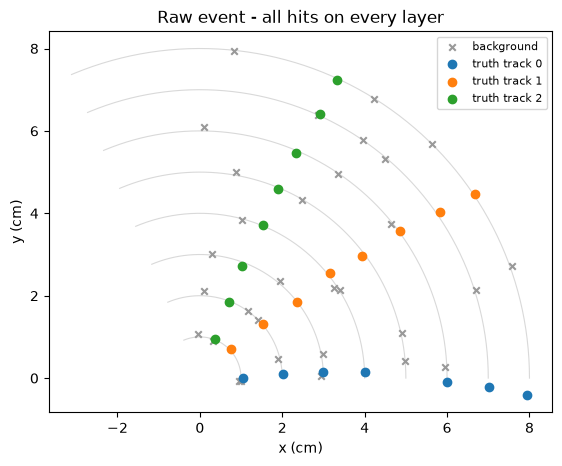

In [3]:
# Raw event display. `model.draw_layers` is a small geometry helper; the hits live in the
# event (signal coloured by truth track, background as grey x).
def draw_layers(ax, radii):
    th = np.linspace(0, np.pi/2 + 0.4, 200)
    for r in radii:
        ax.plot(r*np.cos(th), r*np.sin(th), color="0.85", lw=0.8, zorder=0)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_layers(ax, model.radii)
colors = plt.get_cmap("tab10")
for l in range(len(event.hits)):
    H, T = event.hits[l], event.truth[l]
    bg = T < 0
    ax.scatter(H[bg, 0], H[bg, 1], s=22, c="0.6", marker="x", zorder=2,
               label="background" if l == 0 else None)
    for tid in range(event.n_tracks):
        sel = T == tid
        ax.scatter(H[sel, 0], H[sel, 1], s=36, color=colors(tid), zorder=3,
                   label=f"truth track {tid}" if l == 0 else None)
ax.set_aspect("equal"); ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)")
ax.set_title("Raw event - all hits on every layer"); ax.legend(fontsize=8, loc="upper right")
plt.show()

## Running the CKF

We wrap the model in `CombinatorialKalmanFilter` and call `forward(...)` with the ragged per-layer
hits. The hyper-parameters control the search: the $\chi^2$ gate, the beam width
(`max_candidates`), the allowed holes, the minimum hits to accept a track, and the arbitration
overlap fraction.

In [4]:
from kalman.filters import CombinatorialKalmanFilter

ckf = CombinatorialKalmanFilter(model, max_candidates=8, max_holes=2, min_hits=4, shared_hit_frac=0.3)
tracks = ckf.forward(event.hits, layer_radii=event.radii)

print(f"chi2 gate       : {ckf.chi2_cut:.2f}")
print(f"candidates/seed : {len(ckf.candidates)}")
print(f"accepted tracks : {len(tracks)}\n")
for i, raw in enumerate(ckf.tracks_raw):
    ids = [int(event.truth[l][j]) for (l, j) in raw.hit_ids]
    sig = [t for t in ids if t >= 0]
    maj = max(set(sig), key=sig.count) if sig else -1
    purity = sig.count(maj) / len(ids)
    print(f"  track {i}: {raw.n_hits} hits, chi2/ndf={raw.chi2/raw.n_hits:5.2f}, "
          f"majority truth={maj}, purity={purity:4.0%}, holes={raw.holes}")

chi2 gate       : 9.21
candidates/seed : 7
accepted tracks : 3

  track 0: 8 hits, chi2/ndf= 0.96, majority truth=2, purity= 88%, holes=0
  track 1: 8 hits, chi2/ndf= 1.15, majority truth=1, purity=100%, holes=0
  track 2: 7 hits, chi2/ndf= 0.28, majority truth=0, purity= 86%, holes=1


### Reconstructed tracks

The CKF picks the right hits out of the soup. Found tracks are drawn as colored polylines through the
hits they claimed; rejected background stays grey.

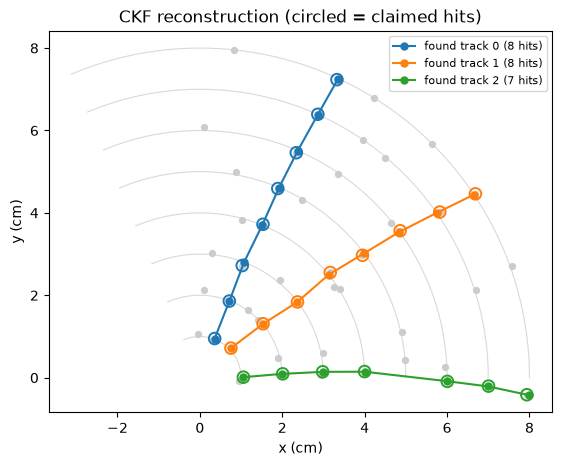

In [5]:
# CKF reconstruction. `tracks` is a KalmanRecordCollection (one KalmanRecord per found
# track); we overlay each track's posterior x-y path with its claimed hits circled.
fig, ax = plt.subplots(figsize=(6.5, 6.5))
draw_layers(ax, model.radii)

# all hits, faint
for l in range(len(event.hits)):
    H = event.hits[l]
    ax.scatter(H[:, 0], H[:, 1], s=18, c="0.8", zorder=1)

for i, rec in enumerate(tracks):
    xy = rec.xk[:, :2]
    ax.plot(xy[:, 0], xy[:, 1], "-o", ms=5, color=colors(i), zorder=4,
            label=f"found track {i} ({len(rec)} hits)")
    z = rec.zk
    ax.scatter(z[:, 0], z[:, 1], s=70, facecolors="none", edgecolors=colors(i),
               linewidths=1.4, zorder=3)
ax.set_aspect("equal"); ax.set_xlabel("x (cm)"); ax.set_ylabel("y (cm)")
ax.set_title("CKF reconstruction (circled = claimed hits)"); ax.legend(fontsize=8, loc="upper right")
plt.show()

## Smoothing the fitted tracks

Once the hits are assigned, each track is a standard Kalman fit — so the RTS **smoother** refines the
state at every layer using information from the whole track. `backward()` returns the smoothed records.

In [6]:
smoothed = ckf.backward()   # RTS smooth each accepted track (uses the forward pass above)
for i, (f, s) in enumerate(zip(tracks, smoothed)):
    # mean position uncertainty (trace of the 2x2 position block) before vs after smoothing
    pf = np.sqrt(np.trace(f.Pk[:, :2, :2], axis1=1, axis2=2)).mean()
    ps = np.sqrt(np.trace(s.Pk[:, :2, :2], axis1=1, axis2=2)).mean()
    print(f"track {i}: mean position sigma  filtered={pf:.4f}  smoothed={ps:.4f} cm")

track 0: mean position sigma  filtered=0.0463  smoothed=0.0323 cm
track 1: mean position sigma  filtered=0.0458  smoothed=0.0323 cm
track 2: mean position sigma  filtered=0.0498  smoothed=0.0361 cm
